# 호텔 예약 취소 예측 — 3일차: 해석 · threshold · 비즈니스 활용

**목표**
1. 최종 LightGBM이 무엇을 보고 판단하는지 — permutation importance, SHAP
2. 예측 확률을 그대로 믿어도 되는지 — 확률 보정(calibration) 상태
3. threshold 정하기 — 활용 시나리오별 비용 기준, **검증 기간에서 정하고 테스트에 적용**
4. 예약 단위가 아닌 **날짜 단위 취소 건수** 예측 — 초과 예약 규모 결정용
5. **XGBoost로 바꿔도 결론이 같은지** — 해석·보정·threshold가 LightGBM에만 해당하는 결과인지 확인
6. 한계와 개선 방향

2일차 확정 사항: 도착일 기준 시간 분할, 최종 피처(`final_features`), LightGBM(`num_leaves=31`).

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from xgboost import XGBClassifier

from src.data import TARGET, load_data, arrival_date, time_split, final_features, split_xy
from src.model import make_model, evaluate, compare

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 50)
SEED = 42
LGBM_PARAMS = dict(n_estimators=500, learning_rate=0.05, num_leaves=31, verbose=-1, random_state=SEED)

In [ ]:
df = load_data()
X, y = split_xy(final_features(df))
arrival = arrival_date(df)
train_idx, valid_idx, test_idx = time_split(df, ["2017-01-01", "2017-05-01"])
dev_idx = train_idx.append(valid_idx)

# 선택용 모델(학습 구간만) — threshold 등 "결정"은 이 모델의 검증 기간 예측으로 내린다(의사결정용 모델)
sel_model = make_model(X, LGBMClassifier(**LGBM_PARAMS), tree=True).fit(X.loc[train_idx], y.loc[train_idx])
# 최종 모델(학습+검증) — 테스트 기간 평가·해석용 (2일차 최종 모델과 동일)
final_model = make_model(X, LGBMClassifier(**LGBM_PARAMS), tree=True).fit(X.loc[dev_idx], y.loc[dev_idx])

X_valid, y_valid = X.loc[valid_idx], y.loc[valid_idx]
X_test, y_test = X.loc[test_idx], y.loc[test_idx]
p_valid = sel_model.predict_proba(X_valid)[:, 1] # 기준값 결정 : el_model이 뽑아낸 p_valid를 가지고 손실 비용 곡선을 돌려서 "손실을 최소화하는 최적의 Threshold는 0.38이다!"라고 결정합니다.
p_test = final_model.predict_proba(X_test)[:, 1] # p_test에 그 기준값을 그대로 적용 : 1번에서 찾은 0.38이라는 커트라인을 최신 모델(final_model)의 p_test에 가져다 대고 "실제 미래 기간(5~8월)에서도 비용이 잘 절감되는가?"를 블라인드 테스트합니다.

compare({"선택용 모델 → 검증": evaluate(sel_model, X_valid, y_valid),
         "최종 모델 → 테스트": evaluate(final_model, X_test, y_test)})

,roc_auc,pr_auc,accuracy,precision,recall,f1
선택용 모델 → 검증,0.9011,0.8564,0.8143,0.8120,0.6386,0.7150
최종 모델 → 테스트,0.8704,0.8278,0.7758,0.8066,0.5880,0.6802


2일차 결과(검증 0.901 / 테스트 0.870)와 같은 모델임을 확인했다. = 어제와 똑같은 수치(검증 0.901, 테스트 0.870)가 출력되었으니, "모델이 2일차와 완전히 동일한 상태로 잘 복원되었음이 증명되었으니 이제 안심하고 3일차 분석으로 들어가자

[ ~ 2016-12-31 ]  :  train_idx (학습 기간)
[ 2017-01-01 ~ 2017-04-30 ] :  valid_idx (검증 기간)
[ 2017-05-01 ~           ] :  test_idx  (테스트 기간, 실전 미래)

- 선택용 모델 → 검증
조건: 2016년 말까지의 데이터(train)로만 학습한 뒤, 2017년 1~4월(valid)을 맞춘 모의고사 성적입니다.결과: ROC-AUC 0.9011, PR-AUC 0.8564, F1 0.7150   역할: 이 모델의 예측값(p_valid)을 바탕으로 3일차의 핵심 작업인 비용 최소화 기준점(Threshold)을 탐색하게 됩니다.

- 최종 모델 → 테스트 (행 2):   조건: 2017년 4월까지의 데이터(train + valid)를 모두 학습한 뒤, 미래 실전 기간인 2017년 5~8월(test)을 맞춘 수능 실전 성적입니다.결과: ROC-AUC 0.8704, PR-AUC 0.8278, F1 0.6802   역할: 위에서 정한 Threshold를 이 모델의 예측값(p_test)에 그대로 적용해 실제 호텔 손실 비용이 얼마나 줄어드는지 최종 검증합니다.

## 1. 모델 해석

### 1-1. Permutation importance (테스트 기간)
열 하나의 값을 무작위로 섞었을 때 ROC-AUC가 얼마나 떨어지는지 본다. 모델 종류와 무관하고, *평가 데이터에서의* 실제 기여를 보여준다.

LightGBM 자체 내장 중요도(feature_importances_)는 카테고리가 많거나 연속형인 변수를 편애하는 왜곡이 있습니다. 이를 방지하기 위해 Permutation Importance(순열 중요도)를 사용

,mean,std
country,0.0995,0.0026
market_segment,0.0744,0.0025
deposit_type,0.0702,0.0008
agent,0.0596,0.0014
total_of_special_requests,0.0449,0.0018
lead_time,0.0340,0.0005
customer_type,0.0211,0.0009
previous_bookings_not_canceled,0.0061,0.0005
adr_per_person,0.0030,0.0003
adr,0.0021,0.0001


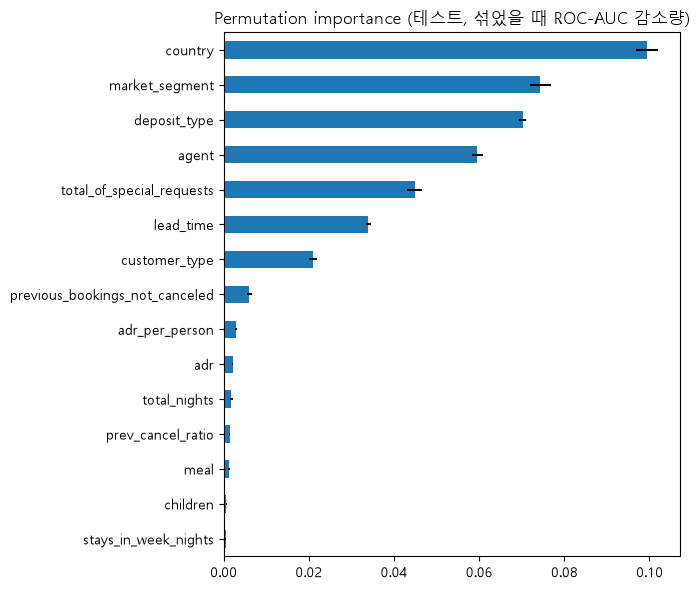

In [ ]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=SEED, n_jobs=1)
perm_imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                        index=X.columns).sort_values("mean", ascending=False)

top = perm_imp.head(15)[::-1]
top["mean"].plot.barh(xerr=top["std"], figsize=(7, 6), color="tab:blue")
plt.title("Permutation importance (테스트, 섞었을 때 ROC-AUC 감소량)")
plt.tight_layout()
perm_imp.head(10).round(4) # 모델 판별력에 가장 치명적인 영향을 주는 top10 피처의 구체적인 감소수치 확인 

In [ ]:
perm_imp.head(10).round(4) # 모델 판별력에 가장 치명적인 영향을 주는 top10 피처의 구체적인 감소수치 확인  / 별도로 분리

- `country`, `market_segment`, `deposit_type`, `agent` — **"누가 어떤 경로로 예약했나"** 가 상위를 차지한다.
    - 예약 취소 여부는 개별 고객의 성향보다 "어떤 국가에서, 어떤 여행사/채널(OTA, 그룹 등)을 통해, 어떤 환불 조건으로 유입되었는가"라는 유통 계약 구조에 의해 1차적으로 결정됨을 보여줍니다. 특히 환불 정책(deposit_type)과 예약 대행사(agent)의 높은 순위는 특정 여행사의 단체 블록 예약 취소 관행이 강하게 반영되어 있음을 시사합니다.
- 그다음이 `total_of_special_requests`, `lead_time` — 고객 개인의 행동 신호.
    -유통 경로가 정해진 뒤, "요청 사항이 많은가(방문 의지가 강함)", "얼마나 먼 미래의 예약인가(취소 변동성 증가)"가 개별 확률을 끌어올리거나 낮추는 보정값 역할을 수행합니다.
- 2일차 파생 피처 중에선 `adr_per_person`, `total_nights`, `prev_cancel_ratio`가 약간 기여하지만 작다(2일차 결론과 일치).
    -2일차에서 확인했던 바와 같이, 파생 피처들이 모델을 망치지는 않지만 유통 구조 변수들에 비해 모델 성능(ROC-AUC)을 좌우하는 결정적 요인은 아님을 입증합니다.

Permutation Importance는 "이 변수가 얼마나 중요한가(크기)"만 알려주고, "어느 방향으로 영향을 미치는가(양/음)"는 알려주지 못합니다.
가설
total_of_special_requests가 높을수록 취소 확률을 실제로 낮추는가? (음의 기여)

lead_time이 길어질수록 취소 확률이 비선형적으로 치솟는가? (양의 기여)

deposit_type == 'Non Refund'가 직관과 반대로 취소 확률을 극단적으로 높이는가? (데이터 아티팩트 검증)

### 1-2. SHAP — 개별 예측을 피처별 기여로 분해

테스트 기간에서 5,000건을 뽑아 `TreeExplainer`로 계산한다. 값은 **log-odds** 단위(+면 취소 쪽).
범주형 열은 정수 코드로 들어가 있으므로, 범주별 해석은 1-3에서 원래 값으로 다시 묶어 본다.

In [ ]:
prep, clf = final_model[:-1], final_model.named_steps["clf"] # SHAP 분석 도구는 Scikit-Learn 파이프라인 전체를 넣으면 속도가 느려지므로, 뒤에 달린 순수 LightGBM 모델(clf)만 따로 뺍니다.
X_test_t = prep.transform(X_test)          # 트리용 전처리 결과 (열 이름 유지)
shap_sample = X_test_t.sample(5000, random_state=SEED) # 연산 속도를 위해 손님 5천명만 무작위 추출 

with warnings.catch_warnings():
    warnings.simplefilter("ignore")        # LightGBM 이진 분류 출력 형식 안내 경고
    shap_values = shap.TreeExplainer(clf).shap_values(shap_sample)
if isinstance(shap_values, list):          # 버전에 따라 [음성, 양성] 리스트로 반환
    shap_values = shap_values[1] # 0(정상방문)말고 1(취소)에 기여한 점수만 보겠다 

# 모든 손님의 점수를 합쳐서 피처별 영향력 지분율 표 만들기 
shap_imp = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_sample.columns).sort_values(ascending=False)
shap_share = (shap_imp / shap_imp.sum()).rename("SHAP 비중")
shap_share.head(10).round(3).to_frame()

,SHAP 비중
deposit_type,0.250
country,0.161
market_segment,0.114
total_of_special_requests,0.093
lead_time,0.077
agent,0.074
customer_type,0.052
prev_cancel_ratio,0.047
arrival_date_month,0.024
previous_bookings_not_canceled,0.014


deposit_type (25.0%): 보증금/환불 조건 하나가 전체 판단의 4분의 1을 좌우합니다. 취소 예측에서 압도적인 단일 1등 변수입니다.   country (16.1%) & market_segment (11.4%): 고객 국적과 예약 유통 채널(온라인 여행사, 오프라인 여행사, 단체 등)이 그 뒤를 잇습니다.   해석: 취소 여부는 개인의 취향보다 "어느 나라에서, 어떤 계약 조건(환불 규정 및 대행 채널)으로 방을 잡았는가"라는 거시적 예약 구조에 의해 모델 판단의 절반 이상(52.5%)이 이미 결정된다는 뜻입니다. 

앞서 본 Permutation Importance와의 결정적 일관성아까 보셨던 순열 중요도(AUC 감소량 순위)와 지금의 SHAP 비중 순위가 상위권(deposit_type, country, market_segment, requests, lead_time)에서 완전히 동일한 순서를 가리키고 있습니다.   이는 모델이 특정 알고리즘의 편향이나 우연에 휘둘린 것이 아니라, 실제 데이터 속 비즈니스 패턴을 매우 일관되게 학습했음을 증명합니다.

모델은 보증금 조건(deposit_type)과 국적/채널을 보고 취소 고위험군/저위험군의 뼈대(52%)를 먼저 세운 뒤, 요청 사항 개수와 리드타임으로 세부 확률을 튜닝하고 있다

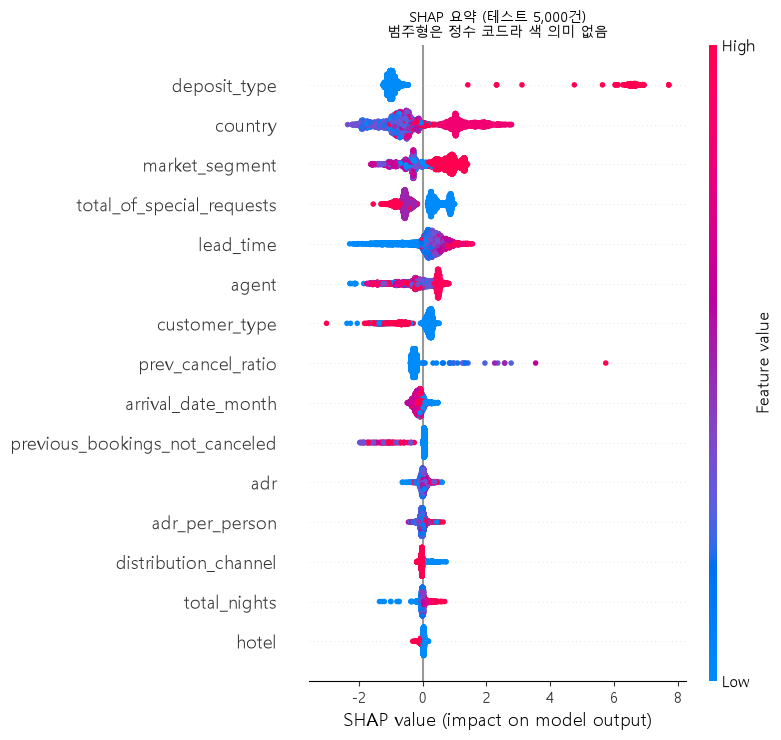

In [5]:
shap.summary_plot(shap_values, shap_sample, max_display=15, show=False)
plt.title("SHAP 요약 (테스트 5,000건)" + chr(10) + "범주형은 정수 코드라 색 의미 없음", fontsize=10)
plt.tight_layout()

- **`deposit_type` 하나가 전체 SHAP의 25%, `country`가 16%** — 두 열이 모델 판단의 40% 이상을 차지한다.
- Permutation importance에서는 `country`가 1등, SHAP에서는 `deposit_type`이 1등. 차이의 이유:
  Non Refund는 테스트에서 약 9%뿐이라 *섞어도 영향받는 행이 적지만*, 해당 행에서는 기여가 매우 크다(아래 1-3).

이 Beeswarm 플롯은 각 피처가 취소 확률을 높이는 쪽(+ 방향, 오른쪽)으로 작용하는지, 아니면 방문 쪽(- 방향, 왼쪽)으로 작용하는지를 한눈에 보여주는 SHAP의 핵심 시각화입니다.   가운데 세로선($0.0$)을 기준으로 오른쪽에 점이 찍히면 "취소 위험 증가", 왼쪽에 찍히면 "방문 확률 증가(취소 위험 감소)"를 의미합니다.   

차트 제목에 적혀 있듯, 범주형 변수는 단순히 내부 정수 인코딩(0, 1, 2...)으로 처리되었기 때문에 빨간색/파란색 자체의 고저 의미는 무시하고 점들의 분포(좌/우 위치)만 보아야 합니다.

모델은 요청사항이 많고 리드타임이 짧으면 '방문할 고객'으로 판단하고, 특정 보증금 조건(deposit_type)이나 위험 국적/채널에 걸리면 '취소할 고객'으로 강하게 밀어붙이고 있습니다.

### 1-3. 범주별 평균 SHAP — 원래 값으로 묶어 보기

In [ ]:
orig = X_test.loc[shap_sample.index] # SHAP를 계산할 때 썼던 5,000개 행의 인덱스를 이용해, 정수 인코딩 이전의 원래 텍스트가 들어있는 테스트 데이터를 가져옵니다.

def shap_by_category(col, top_n=6):
    s = pd.Series(shap_values[:, shap_sample.columns.get_loc(col)], index=shap_sample.index)
    out = s.groupby(orig[col].fillna("(없음)")).agg(건수="size", 평균_SHAP="mean")
    out["실제_취소율"] = y_test.loc[shap_sample.index].groupby(orig[col].fillna("(없음)")).mean()
    return out.sort_values("건수", ascending=False).head(top_n).round(3)

for col in ["deposit_type", "country", "market_segment", "customer_type"]:
    print(f"[{col}]")
    display(shap_by_category(col))

[deposit_type]


,건수,평균_SHAP,실제_취소율
deposit_type,,,
No Deposit,4556,-0.972,0.337
Non Refund,439,6.598,1.000
Refundable,5,2.296,1.000


[country]


,건수,평균_SHAP,실제_취소율
country,,,
PRT,1441,1.296,0.609
GBR,698,-0.992,0.291
FRA,422,-0.907,0.273
DEU,417,-1.242,0.211
ESP,323,-0.564,0.368
IRL,201,-0.816,0.358


[market_segment]


,건수,평균_SHAP,실제_취소율
market_segment,,,
Online TA,2927,0.806,0.426
Offline TA/TO,852,-0.639,0.323
Direct,552,-0.207,0.179
Groups,491,-0.472,0.656
Corporate,139,-0.425,0.223
Aviation,21,-0.014,0.143


[customer_type]


,건수,평균_SHAP,실제_취소율
customer_type,,,
Transient,4227,0.207,0.440
Transient-Party,623,-0.784,0.169
Contract,123,-1.202,0.114
Group,27,-1.050,0.037


딱 하나만 기억하시면 됩니다: "평균_SHAP가 플러스(+)면 취소 쪽으로 밀어붙인 거고, 마이너스(-)면 방문 쪽으로 당긴 것 

- 1번 : 보통 "환불 불가로 예약하면 돈 아까워서라도 오겠지?"라고 생각하지만, 실제 데이터는 정반대입니다. 여행사나 단체에서 방을 대량으로 묶어둘 때 '환불 불가'로 잡아두고 나중에 통째로 날려버리는 관행이 있는 것입니다.

모델은 이걸 귀신같이 학습해서 "Non Refund 딱지가 붙어있으면 취소 점수를 +6.6점이나 줘서 무조건 취소된다고 판단"하고 있는 것입니다.


- 2번 이게 무슨 뜻일까? (핵심 인사이트):

비행기 표 끊고 멀리서 오는 유럽 외국인 관광객들은 예약을 취소하지 않고 진짜로 옵니다. 반면 현지 내국인(포르투갈)들은 가볍게 예약했다가 취소하는 비중이 훨씬 높다는 걸 모델이 정확히 짚어낸 것입니다.

-3번
온라인 앱으로 손쉽게 클릭해서 예약한 고객들은 취소 버튼도 쉽게 누르고, 호텔 홈페이지나 프론트로 직접 예약한 손님들은 진짜 묵으러 오는 경향이 큽니다.

- 4번
Transient(순수 개인 예약)는 취소 변동성이 큰 반면, Contract나 Transient-Party처럼 조직·계약으로 묶인 손님은 방문 확정성이 매우 높다

=> 모델은 상식과 달리 Non Refund(환불 불가) 조건을 취소의 가장 결정적 단서(+6.6)로 보고 있으며, 포르투갈 내국인(PRT)이거나 온라인 예약(Online TA)일수록 취소 위험을 높게 책정하고 있다.

- **Non Refund → 평균 +6.6 log-odds.** 확률로 치면 거의 "무조건 취소"로 밀어붙이는 크기다. 1·2일차에 본 여행사 일괄 취소 패턴을 모델이 그대로 학습했다.
- **PRT(포르투갈) → +1.3**, 영국·프랑스·독일 등 → −0.9 ~ −1.2. 2일차에 의심한 "취소 건은 국적이 기본값 PRT로 남는다"는 가능성과 같은 방향이다.
- `Online TA`(온라인 여행사)는 취소 쪽, `Contract`·`Group` 고객 유형은 유지 쪽.
- `Groups` 세그먼트는 실제 취소율이 66%로 높은데 평균 SHAP은 오히려 음수(−0.47)다. 단체 예약의 높은 취소는 이미 `deposit_type`(Non Refund)이 설명하고 있어서,
  *보증금 조건이 같다면* 단체라는 사실 자체는 유지 쪽이라는 뜻이다. SHAP은 **다른 피처를 감안한 뒤의 기여**라서 단순 취소율과 다를 수 있다.

### 1-4. 수치형 피처의 효과 방향 = shap의존도 산점도
-가운데 가로선(ax.axhline(0))인 0보다 위면 취소 위험 증가($+$), 0보다 아래면 방문 확률 증가($-$)를 나타냅니다.

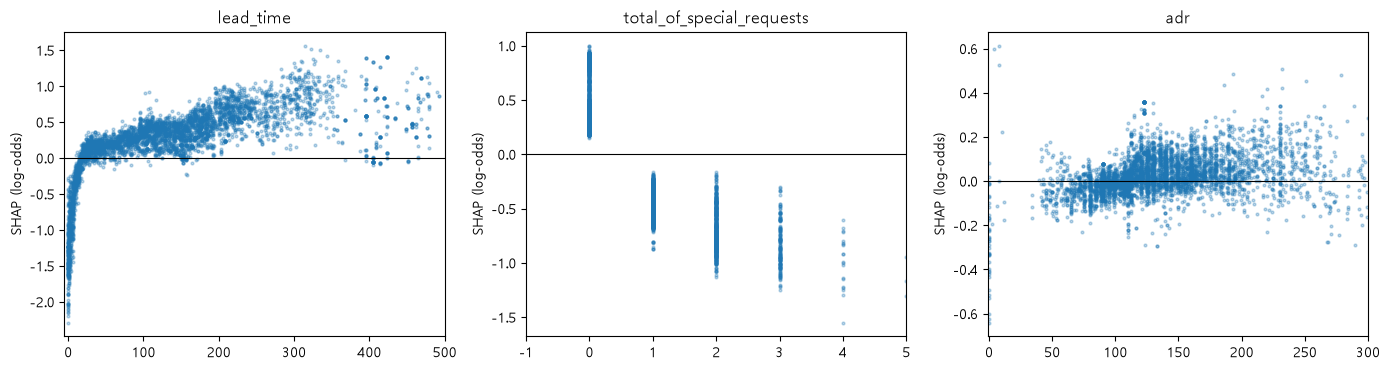

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, xmax in zip(axes, ["lead_time", "total_of_special_requests", "adr"], [500, 5, 300]):
    j = shap_sample.columns.get_loc(col)
    ax.scatter(shap_sample[col], shap_values[:, j], s=4, alpha=0.3)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlim(-1 if col != "lead_time" else -5, xmax)
    ax.set_title(col); ax.set_ylabel("SHAP (log-odds)")
plt.tight_layout()

- `lead_time`: 예약을 일찍 할수록 취소 쪽. 처음 몇 주 사이에 급하게 올라가고 이후 완만 — 직전 예약은 거의 취소하지 않는다.
- `total_of_special_requests`: 요청이 1개만 있어도 유지 쪽으로 크게 이동 — **요청을 남긴 고객은 실제로 올 생각이 있는 고객**이라는 해석이 자연스럽다.
- `adr`(1박 요금): 효과가 작고 방향이 섞여 있다.

**해석 정리**
- 모델의 판단은 크게 ① 예약 경로·계약 조건(`deposit_type`, `market_segment`, `agent`, `customer_type`) ② 국적 ③ 고객 행동 신호(`lead_time`, 특별 요청)로 나뉜다.
- ①·②가 SHAP 비중의 대부분이고, 둘 다 2일차에 **일반화 위험**으로 기록한 열이다. 모델 성능의 상당 부분이 "이 데이터의 특정 여행사 관행·기록 방식"에 기대고 있을 수 있다.

가운데 가로 기준선($0.0$)을 기준으로 위쪽($+$)은 취소 위험 증가, 아래쪽($-$)은 방문 확정 증가입니다. 

lead_time (예약 리드타임): 전형적인 로그 곡선(포화 형태)형태:   0 ~ 20일: 점들이 $-2.0$ 부근 바닥에서 시작해 가파르게 수직 상승합니다.   약 20~30일 지점: 정확히 $0.0$ 선을 통과합니다 (취소 위험 중립).   100일 이상: $+0.5 \sim +1.0$ 부근에서 더 이상 급격히 오르지 않고 완만한 포화(로그형 곡선)를 그립니다.   해석:체크인 2~3주 전 예약은 "거의 무조건 방문하는 초안전 고객"입니다.   예약이 100일 이상 남으면 취소 변동성이 최대치에 도달하며, 100일 남은 손님이나 300일 남은 손님이나 취소 위험도는 비슷하게 높은 상태로 유지됩니다


2. total_of_special_requests (특별 요청 사항): 극적인 절벽형 하강형태:   0개: 점들이 $+0.2 \sim +1.0$ 사이 위쪽에만 모여 있습니다.   1개: 점들이 즉시 $-0.2 \sim -0.8$ 아래로 수직 낙하(절벽)합니다.   2개 이상: 점진적으로 더 깊은 음수($-1.0 \sim -1.5$)로 내려갑니다.   해석:가장 중요한 분기점은 "요청 사항이 0개냐, 1개 이상이냐"입니다.   요구사항을 단 하나라도 입력한 순간 모델은 해당 예약을 취소 고위험군에서 즉시 제외하며, 2개 이상부터는 확정 투숙객으로 강하게 분류합니다

사람의 심리에서 요구사항 0개와 1개는 단순 숫자 차이가 아닙니다.

"앱 켜서 날짜 누르고 대충 결제해 둔 손님(0개)"과 "기왕 가는 거 고층 배정해 달라거나 침대 더 놔달라고 손가락을 몇 번 더 움직인 손님(1개)" 사이의 체감 정성과 확정 의지의 차이가 너무나 크기 때문에, 모델의 판단 점수도 완만하게 깎이지 않고 절벽처럼 툭 떨어지는 것입니다.


3. adr (객실 단가): Y축 스케일이 작은 평평한 띠   형태:   좌측 두 그래프(Y축 범위: $-2 \sim +1.5$)와 달리, 세 번째 그래프는 Y축 범위 자체가 $-0.6 \sim +0.6$으로 매우 좁습니다.   대부분의 점이 $0.0$ 선 주변에 얇게 밀집해 있고, 가격이 100~200유로대로 올라가더라도 $+0.1 \sim +0.2$ 수준의 미미한 양의 기여에 그칩니다.   해석:"방값이 비싸서 취소한다"는 일반적인 직관과 달리, 객실 요금 자체는 취소 예측에 미치는 독자적 영향력이 매우 미미합니다.   고객의 취소 결정을 좌우하는 것은 숙박비가 아니라 예약 리드타임과 환불 정책, 유통 경로입니다.   

## 2. 확률 보정 상태 — 예측 확률을 그대로 믿어도 되나? >> 이건 비즈니스적 측면


threshold를 비용으로 정하거나, 확률을 더해 취소 건수를 예측하려면 확률 자체가 맞아야 한다.

,평균 예측 확률,실제 취소율
검증,0.326,0.365
테스트,0.339,0.405


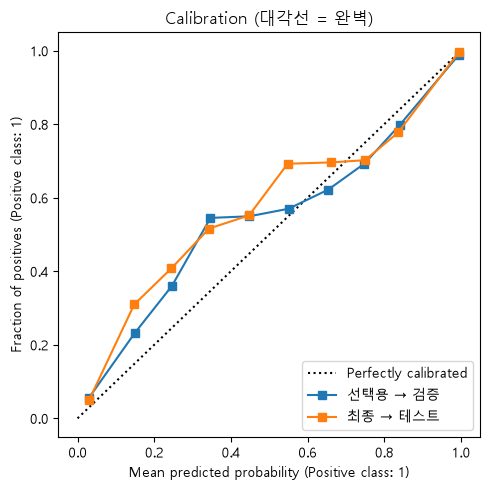

In [8]:
fig, ax = plt.subplots(figsize=(5, 5))
CalibrationDisplay.from_predictions(y_valid, p_valid, n_bins=10, ax=ax, name="선택용 → 검증")
CalibrationDisplay.from_predictions(y_test, p_test, n_bins=10, ax=ax, name="최종 → 테스트")
ax.set_title("Calibration (대각선 = 완벽)")
plt.tight_layout()

pd.DataFrame({"평균 예측 확률": [p_valid.mean(), p_test.mean()],
              "실제 취소율": [y_valid.mean(), y_test.mean()]}, index=["검증", "테스트"]).round(3)

- 두 기간 모두 곡선이 대각선 **위**에 있다 → 모델이 취소 확률을 **낮게** 예측한다. 특히 0.1 ~ 0.6 구간(최대 15%p 차이). 0.8 이상의 확신 구간은 대체로 맞다.
- 테스트에서는 평균 예측 33.9% vs 실제 40.5%로 차이가 더 크다. 테스트 기간 취소율이 학습 기간보다 높아진(2일차 확인) **분포 변화**를 모델이 따라가지 못한 결과다.
- 순위(ROC-AUC)는 괜찮아도 **확률의 절대값은 과소 추정**된다는 점을 threshold 해석과 4장 건수 예측에서 감안해야 한다.


모델이 위험도를 전체적으로 낮게 보고 있으므로, 기본 기준선인 $0.5$를 그대로 두면 취소 위험 고객을 대거 놓치게 됩니다. 따라서 기준선을 $0.5$보다 아래(예: $0.35 \sim 0.4$)로 낮춰 잡아야 실제 비즈니스 손실을 줄일 수 있습니다.

대각선 점선 ($y = x$): 완벽한 상태입니다. 모델이 예측한 확률과 실제 취소율이 1:1로 일치하는 이상적인 선입니다.곡선이 대각선보다 아래에 위치:모델이 예측한 확률 > 실제 취소율과신(Overconfident): 모델이 취소 확률을 실제보다 너무 높게 부풀려서 보고 있습니다.

곡선이 대각선보다 위에 위치:

모델이 예측한 확률 < 실제 취소율

과소평가(Underconfident): 모델이 취소 위험을 실제보다 너무 안일하게 낮게 보고 있습니다.

검증(Valid) vs 테스트(Test):

검증 세트에서만 대각선에 맞고 테스트에서 엉망이 되는지, 아니면 두 데이터 모두에서 일관되게 대각선 궤적을 잘 따라가는지 확인합니다.

## 3. threshold — 활용 시나리오별 비용 기준

- 오버부킹 사고는 호텔 평판과 보상 비용이 너무 크기 때문에, "취소 확률이 80% 이상으로 거의 100% 확실할 때"만 극도로 조심스럽게 방을 재판매해야 합니다. (Threshold = 0.80)

### 3-1. 시나리오와 비용 가정

예약 1건에 대해 "취소될 것"으로 표시(양성)할지 정한다. 비용은 **빈 방 1개 손실 = 1** 을 기준으로 한 상대값이며, 실제 값은 호텔이 정해야 하는 **가정**이다.

| 시나리오 | 양성 표시 시 하는 일 | 오탐(FP) 비용 | 놓침(FN) 비용 | 이론상 threshold* |
|---|---|---|---|---|
| A. 확인 연락 | 도착 전 연락·리마인드, 재확인 요청 | 1/5 (연락 비용·약간의 불편) | 1 (빈 방) | 0.17 |
| B. 선제 재판매 | 해당 객실을 다른 고객에게 미리 판매 | 4 (온 손님 방이 없음 → 보상·평판) | 1 (빈 방) | 0.80 |

\* 확률이 정확하다면 비용이 최소가 되는 threshold는 `FP 비용 / (FP 비용 + FN 비용)`. 2장에서 본 과소 추정 때문에 실제 최적값과는 다를 수 있으므로 **검증 기간에서 직접 찾는다.**
(계산 편의상 A는 FP=1, FN=5로 같은 비율을 쓴다.)

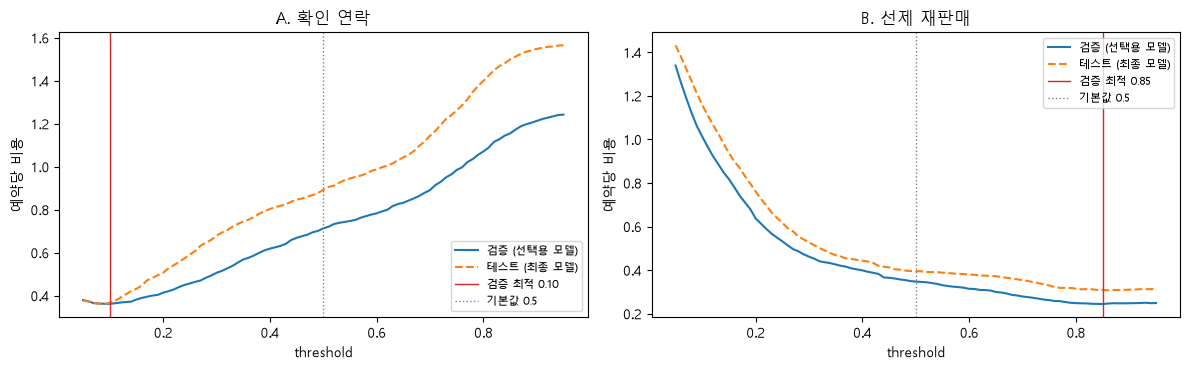

In [9]:
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
SCENARIOS = {"A. 확인 연락": {"fp": 1, "fn": 5}, "B. 선제 재판매": {"fp": 4, "fn": 1}}

def cost_per_booking(y_true, proba, t, fp, fn):
    y_true, flag = np.asarray(y_true), proba >= t
    return (fp * (flag & (y_true == 0)).sum() + fn * (~flag & (y_true == 1)).sum()) / len(y_true)

def summary_at(y_true, proba, t, fp, fn):
    flag = proba >= t
    return {"threshold": t, "예약당 비용": cost_per_booking(y_true, proba, t, fp, fn),
            "표시 비율": flag.mean(), "precision": precision_score(y_true, flag),
            "recall": recall_score(y_true, flag)}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
chosen = {}
for ax, (name, c) in zip(axes, SCENARIOS.items()):
    cv = [cost_per_booking(y_valid, p_valid, t, **c) for t in thresholds]
    ct = [cost_per_booking(y_test, p_test, t, **c) for t in thresholds]
    chosen[name] = thresholds[int(np.argmin(cv))]
    ax.plot(thresholds, cv, label="검증 (선택용 모델)")
    ax.plot(thresholds, ct, label="테스트 (최종 모델)", ls="--")
    ax.axvline(chosen[name], color="tab:red", lw=1, label=f"검증 최적 {chosen[name]:.2f}")
    ax.axvline(0.5, color="gray", lw=1, ls=":", label="기본값 0.5")
    ax.set_title(name); ax.set_xlabel("threshold"); ax.set_ylabel("예약당 비용"); ax.legend(fontsize=8)
plt.tight_layout()

머신러닝 기본값인 $0.5$(회색 점선)를 썼을 때 호텔이 얼마나 큰 손해를 보는지"와 "검증 기간에서 고른 최적 threshold(빨간 실선)가 미래 테스트 기간에서도 똑같이 비용을 최소화하는가"

a.
threshold가 커질수록(즉, 의심을 덜 하고 문자를 덜 보낼수록) 예약당 비용이 $0.4$ 미만에서 $1.2 \sim 1.6$까지 폭등합니다.   회색 점선($0.5$)에서는 비용이 약 $0.7 \sim 0.9$ 수준입니다.
문자 발송 비용은 아주 저렴한 반면, 취소를 놓쳐 방을 날리는 손해(FN)는 5배나 큽니다.따라서 "취소 확률이 $10%$만 넘어도 일단 전부 확인 연락을 돌리는 것"이 기본값 $0.5$를 쓰는 것보다 비용을 절반 이하로 줄이는 최적의 전략이 됩니다.   주황색 테스트 점선도 파란색 검증선과 마찬가지로 $0.10$ 근처에서 가장 낮은 비용을 기록하므로, 미래 시점에서도 이 기준이 완벽하게 들어맞습니다.   


b.
최적 지점: 검증 기준 최적 threshold = 0.85   비용 곡선 흐름:threshold가 낮을 때는 비용이 $1.4$ 이상으로 치솟아 있다가, $0.85$ 부근으로 가면서 $0.25 \sim 0.3$ 수준으로 뚝 떨어집니다.   회색 점선($0.5$)에서는 아직 비용이 $0.35 \sim 0.40$대로 내려오지 못했습니다.   비즈니스 의미:방을 중복 판매했다가 손님이 실제로 와버리면(FP) 배상 비용과 평판 타격(비용 4)이 막대합니다.따라서 어설픈 확률($0.5$)에서는 절대 방을 미리 팔면 안 되며, "취소 확률이 $85\%$ 이상으로 거의 확실할 때만 아주 좁게 선제 재판매를 해야 손실이 최소화"됩니다.   

In [10]:
rows = {}
for name, c in SCENARIOS.items():
    ct = [cost_per_booking(y_test, p_test, t, **c) for t in thresholds]
    rows[(name, "기본값 0.5")] = summary_at(y_test, p_test, 0.5, **c)
    rows[(name, "검증에서 고른 값")] = summary_at(y_test, p_test, chosen[name], **c)
    rows[(name, "(사후 참고) 테스트 최적")] = summary_at(y_test, p_test, thresholds[int(np.argmin(ct))], **c)
threshold_results = pd.DataFrame(rows).T
threshold_results.index.names = ["시나리오", "threshold 선택"]
threshold_results.astype(float).round(3)

threshold  예약당 비용  표시 비율  precision  recall
시나리오      threshold 선택                                               
A. 확인 연락  기본값 0.5              0.50   0.892  0.296      0.807   0.588
          검증에서 고른 값            0.10   0.367  0.674      0.577   0.959
          (사후 참고) 테스트 최적       0.09   0.361  0.693      0.568   0.970
B. 선제 재판매 기본값 0.5              0.50   0.396  0.296      0.807   0.588
          검증에서 고른 값            0.85   0.309  0.109      0.977   0.262
          (사후 참고) 테스트 최적       0.86   0.308  0.105      0.987   0.255

- **검증 기간에서 고른 threshold가 테스트에서도 사후 최적값과 거의 같다** (A: 0.10 vs 0.09, B: 0.85 vs 0.86). 기간이 바뀌어도 threshold 선택은 안정적이다.
- **A. 확인 연락** (threshold 0.10): 실제 취소의 **96%** 를 잡는 대신 예약의 67%에 연락한다. 0.5 대비 예약당 비용이 약 60% 줄어든다.
  다만 67%면 사실상 "거의 다 연락"이라, 연락 인력이 한정되면 3-2처럼 **상위 몇 %만 연락**하는 방식이 현실적이다.
- **B. 선제 재판매** (threshold 0.85): 예약의 11%만 골라내고 그중 **98%가 실제 취소** — 틀리면 비싼 결정이라 확실한 건만 고른다. 실제 취소의 26%만 잡는다.
- 두 시나리오 모두 **기본값 0.5는 최적이 아니다.** threshold는 모델이 아니라 비즈니스 비용이 정한다.

### 3-2. 연락 인력이 한정될 때 — 상위 k%만 연락

확률 순위만 쓰므로 2장의 과소 추정 영향을 받지 않는다.

In [11]:
order = np.argsort(-p_test)
y_sorted = y_test.values[order]
topk = {}
for k in [0.05, 0.10, 0.20, 0.30, 0.40]:
    n = int(len(y_sorted) * k)
    topk[f"상위 {k:.0%}"] = {"연락 건수": n, "그중 실제 취소율(precision)": y_sorted[:n].mean(),
                             "전체 취소 중 포착(recall)": y_sorted[:n].sum() / y_sorted.sum(),
                             "무작위 대비 배율(lift)": y_sorted[:n].mean() / y_sorted.mean()}
pd.DataFrame(topk).T.round(3)

,연락 건수,그중 실제 취소율(precision),전체 취소 중 포착(recall),무작위 대비 배율(lift)
상위 5%,1109.0,1.000,0.123,2.466
상위 10%,2219.0,0.993,0.245,2.449
상위 20%,4439.0,0.861,0.425,2.124
상위 30%,6659.0,0.806,0.596,1.987
상위 40%,8879.0,0.734,0.724,1.810


- 예약의 상위 20%만 연락해도 그중 대부분이 실제 취소이고, 무작위로 연락할 때보다 2배 이상 효율적이다.
- 모델이 계산한 취소 확률이 가장 높은 위험 고객부터 일렬로 줄을 세웠을 때, 맨 앞에 선 5%의 고객"

방금 A 시나리오(확인 연락)에서 최적 기준(0.10)을 썼더니 문제가 하나 생겼습니다.

"전체 예약의 67%한테 다 연락을 돌려야 한다"는 점입니다.

만약 오늘 예약이 1,000건 들어왔다면 직원이 670명에게 일일이 전화를 걸거나 알림톡을 보내야 합니다. 호텔 프론트 인력으로는 감당이 안 됩니다.

현실에서는 "우리 직원 2명이 오늘 하루 동안 연락 돌릴 수 있는 최대 인원은 50명(전체의 5%)뿐이다" 같은 인력/예산 제약이 반드시 생깁니다.

취하는 방식이 '상위 5% 전략'입니다
줄 세우기: 오늘 들어온 손님 1,000명을 모델이 매긴 '취소 확률' 순서대로 1등(99%)부터 1,000등(1%)까지 내림차순 정렬합니다.

50명만 딱 자르기 (상위 5%): 취소 위험이 가장 극심한 상위 1번~50번 손님만 골라냅니다.

행동(액션)하기: 직원은 전체 670명을 다 보지 않고, 이 상위 5% 손님에게만 집중적으로 연락을 돌려 예약 확인을 받습니다.

### 3-3. "확실한 취소"로 분류된 예약은 어떤 예약인가
시나리오 B에서 골라낸 예약(확률 ≥ 검증 최적값)의 구성을 본다.

In [12]:
flag_b = p_test >= chosen["B. 선제 재판매"]
sure = X_test[flag_b]
pd.DataFrame({
    "선택된 예약": [flag_b.sum(), sure["deposit_type"].eq("Non Refund").mean(),
                  sure["country"].eq("PRT").mean(), sure["market_segment"].isin(["Groups", "Offline TA/TO"]).mean()],
    "테스트 전체": [len(X_test), X_test["deposit_type"].eq("Non Refund").mean(),
                  X_test["country"].eq("PRT").mean(), X_test["market_segment"].isin(["Groups", "Offline TA/TO"]).mean()],
}, index=["건수", "Non Refund 비율", "PRT 비율", "단체·오프라인 여행사 비율"]).round(3)

,선택된 예약,테스트 전체
건수,2412.000,22198.000
Non Refund 비율,0.840,0.091
PRT 비율,0.867,0.295
단체·오프라인 여행사 비율,0.830,0.265


- 모델이 "확실하다"고 고른 예약은 대부분 **Non Refund · 포르투갈 · 단체/오프라인 여행사** 예약이다.
- 즉 시나리오 B는 실질적으로 "**여행사 블록 예약을 상대로 초과 판매한다**"는 규칙과 비슷하다. 모델 없이도 세울 수 있는 규칙일 수 있고,
  이 관행이 바뀌면(여행사 계약 조건 변경 등) 바로 무너진다 → 운영 시 이 세그먼트의 취소율을 따로 모니터링해야 한다.
    - 운영 시 따로 모니터링해야 한다"는 말은, 실무에서 호텔 예약 관리 시스템(PMS)이나 데이터 대시보드에 구체적인 업무 규칙(Action Plan)을 심어두라는 뜻

    - 여기서 세그먼트란
    특정 공통 조건들로 묶어낸 고객 집단"을 뜻합니다.

방금 코드와 분석에서 짚어낸 바로 그 세그먼트는 구체적으로 다음 3가지 조건이 동시에 걸려 있는 [환불 불가 + 포르투갈 내국인 + 단체/여행사] 예약 묶음

모델이 "취소 확률 85% 이상"이라고 찍은 고객들을 까봤더니, 바로 이 마지막 집단에 몰려 있었습니다. 즉, 호텔 전체 손님이 아니라 "현지 여행사가 방을 대량으로 선점해 뒀다가 일정 맞춰 통째로 날려버리는 특수 집단" 하나를 콕 집어 '이 세그먼트'라고 부르는 것입니다 

지적하신 내용: "모델 없이도 'Non Refund + PRT + 단체'면 취소라고 룰(Rule)을 짤 수 있지 않나?"분석가의 답변 포인트:맞습니다. 모델의 초고위험 판단은 사실상 특정 비즈니스 룰과 일치합니다.하지만 룰 기반(Rule-based) 시스템은 경계선에 있는 고객(예: PRT 내국인이지만 요청사항이 2개 있고 리드타임이 5일인 정상 방문객)을 예외 처리하지 못하고 기계적으로 튕겨냅니다.머신러닝 모델은 거시적인 룰을 기본 뼈대로 잡되, 세부 행동 피처(lead_time, special_requests 등)를 통해 개별 고객의 미세한 예외를 걸러주는 필터 역할을 수행한다는 점에서 단순 조건문(if-else)보다 우위에 있습니다.2. 운영 모니터링: 데이터 드리프트(Data Drift)와 도메인 붕괴 리스크지적하신 내용: "여행사 계약 관행이 바뀌면 바로 무너진다 $\rightarrow$ 세그먼트 취소율 모니터링 필수"분석가의 답변 포인트:모델이 학습한 가장 강력한 신호(Signal)가 비즈니스 관행(Non Refund 블록 부킹)에 강하게 의존하고 있기 때문에, 외부 계약 정책 변경에 극도로 취약한 단일 장애점(SPOF, Single Point of Failure)을 안고 있습니다.따라서 실제 시스템 배포 후에는 모델 전체 성능(Overall AUC)만 볼 것이 아니라, 해당 서브그룹(Non Refund & Groups)의 취소율 추이를 추적하는 전용 데이터 모니터링 대시보드를 반드시 구축해야 합니다.만약 여행사 정책 변경으로 이 세그먼트의 취소율이 급락(정상 투숙 증가)할 경우, 모델 재학습 전까지 시나리오 B(오버부킹) 자동 실행을 즉시 중단(Kill Switch)하는 방어 로직이 필요하다는 결론으로 자연스럽게 이어집니다.

## 4. 날짜 단위 취소 건수 예측 — 초과 예약 규모 정하기

초과 예약은 개별 예약이 아니라 "**그날 몇 건이 취소될까**"로 정한다. 예약별 취소 확률을 도착일·호텔별로 더하면 예상 취소 건수가 된다.
호텔 프론트 데스크와 객실 관리팀이 매일 아침 볼 수 있는 '일별 취소 객실 수'를 모델로 합산해서 예측해 보고, 실제와 얼마나 잘 맞는지 검증하는 코드

호텔·날짜 246개 | 상관계수 0.974 | 평균 절대 오차 7.0건 | 평균 편향 -6.0건 (하루 평균 실제 취소 36.6건)


,하루_평균_실제,하루_평균_예측,편향_비율
hotel,,,
City Hotel,52.618,48.257,-0.083
Resort Hotel,20.561,12.912,-0.372


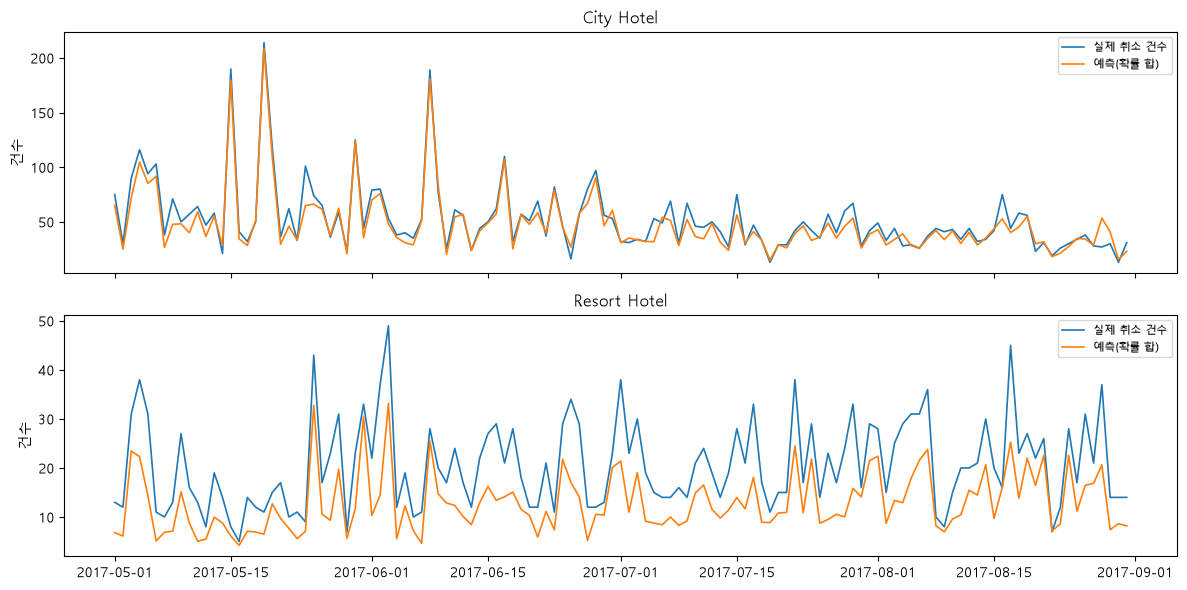

In [13]:
daily = (pd.DataFrame({"예측": p_test, "실제": y_test.values,
                       "hotel": df.loc[test_idx, "hotel"].values, "도착일": arrival.loc[test_idx].values})
         .groupby(["hotel", "도착일"]).agg(예약수=("실제", "size"), 예측_취소=("예측", "sum"), 실제_취소=("실제", "sum")))
err = daily["예측_취소"] - daily["실제_취소"]
print(f"호텔·날짜 {len(daily)}개 | 상관계수 {daily[['예측_취소', '실제_취소']].corr().iloc[0, 1]:.3f} | "
      f"평균 절대 오차 {err.abs().mean():.1f}건 | 평균 편향 {err.mean():+.1f}건 (하루 평균 실제 취소 {daily['실제_취소'].mean():.1f}건)")
display(daily.groupby(level="hotel").agg(하루_평균_실제=("실제_취소", "mean"), 하루_평균_예측=("예측_취소", "mean"))
        .assign(편향_비율=lambda d: d["하루_평균_예측"] / d["하루_평균_실제"] - 1).round(3))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, hotel in zip(axes, ["City Hotel", "Resort Hotel"]):
    d = daily.loc[hotel]
    ax.plot(d.index, d["실제_취소"], label="실제 취소 건수", lw=1.2)
    ax.plot(d.index, d["예측_취소"], label="예측(확률 합)", lw=1.2)
    ax.set_title(hotel); ax.legend(fontsize=8); ax.set_ylabel("건수")
plt.tight_layout()

- 날짜별 취소 건수의 **오르내림은 잘 따라간다**(상관 0.97). City Hotel의 큰 단체 취소가 몰린 날(하루 200건 안팎)도 거의 정확히 예측한다 — 대부분 Non Refund 블록 예약이라 확률이 1에 가깝기 때문.
- 하지만 전체적으로 **꾸준히 적게 예측한다**(하루 평균 약 6건, 약 16% 과소) — 2장의 과소 추정이 그대로 쌓인 결과다.
- 과소 추정은 **Resort Hotel에서 훨씬 크다**(City −8% vs Resort −37%, 위 표). Non Refund 블록 예약이 대부분 City Hotel에 몰려 있어(1·2일차),
  Resort는 확률이 과소 추정되는 중간 구간 예약 비중이 큰 것으로 추정된다(3일차에 구간별로 확인하지는 않음). 호텔별로 따로 보정할 필요가 있다.
- 이 숫자를 그대로 초과 예약 규모로 쓰면 *덜* 초과 예약하게 되므로 보수적인 쪽으로 틀린다(손님을 돌려보내는 위험은 적고, 빈 방이 조금 남는다).
  개선하려면 최근 몇 달의 실제 취소율로 확률을 주기적으로 재보정하는 방법이 있다(→ 6장).

## 5. XGBoost로 바꿔도 결론이 같은가

2일차 검증 기간에서 XGBoost(`max_depth=6`)는 LightGBM과 사실상 동률이었다(ROC-AUC 0.9007 vs 0.9011).
그렇다면 1~4장의 결론(해석, 확률 과소 추정, threshold, 건수 예측)이 **LightGBM 특유의 결과인지, 이 데이터에서 나오는 결과인지** 확인한다.
LightGBM과 똑같이 선택용(학습 구간)·최종(학습+검증) 모델을 만들고, threshold는 검증 기간에서 고른다.

In [14]:
XGB_PARAMS = dict(n_estimators=500, learning_rate=0.05, max_depth=6, tree_method="hist", n_jobs=-1, random_state=SEED)
xgb_sel = make_model(X, XGBClassifier(**XGB_PARAMS), tree=True).fit(X.loc[train_idx], y.loc[train_idx])
xgb_final = make_model(X, XGBClassifier(**XGB_PARAMS), tree=True).fit(X.loc[dev_idx], y.loc[dev_idx])
probs = {"LightGBM": (p_valid, p_test),
         "XGBoost": (xgb_sel.predict_proba(X_valid)[:, 1], xgb_final.predict_proba(X_test)[:, 1])}

def daily_bias(proba):  # 4장과 같은 방식: 호텔·도착일별 예측 합 − 실제 합의 평균
    g = pd.DataFrame({"예측": proba, "실제": y_test.values, "hotel": df.loc[test_idx, "hotel"].values,
                      "도착일": arrival.loc[test_idx].values}).groupby(["hotel", "도착일"])[["예측", "실제"]].sum()
    return (g["예측"] - g["실제"]).mean()

robust = {}
for m, (pv, pt) in probs.items():
    r = {"테스트 ROC-AUC": roc_auc_score(y_test, pt), "테스트 PR-AUC": average_precision_score(y_test, pt),
         "평균 예측 확률(테스트)": pt.mean(), "실제 취소율(테스트)": y_test.mean()}
    for name, c in SCENARIOS.items():
        t = thresholds[int(np.argmin([cost_per_booking(y_valid, pv, t, **c) for t in thresholds]))]
        r[f"{name[:1]} threshold(검증)"] = t
        r[f"{name[:1]} 예약당 비용(테스트)"] = cost_per_booking(y_test, pt, t, **c)
    r["일별 취소 건수 편향"] = daily_bias(pt)
    robust[m] = r
robust = pd.DataFrame(robust)
robust.round(3)

,LightGBM,XGBoost
테스트 ROC-AUC,0.870,0.869
테스트 PR-AUC,0.828,0.825
평균 예측 확률(테스트),0.339,0.341
실제 취소율(테스트),0.405,0.405
A threshold(검증),0.100,0.090
A 예약당 비용(테스트),0.367,0.365
B threshold(검증),0.850,0.840
B 예약당 비용(테스트),0.309,0.311
일별 취소 건수 편향,-6.005,-5.827


SHAP 비중도 같은 5,000건으로 비교한다 (LightGBM 순서 기준 상위 10개).

In [15]:
xgb_prep, xgb_clf = xgb_final[:-1], xgb_final.named_steps["clf"]
xgb_shap = shap.TreeExplainer(xgb_clf).shap_values(xgb_prep.transform(X_test).loc[shap_sample.index])
xgb_imp = pd.Series(np.abs(xgb_shap).mean(axis=0), index=shap_sample.columns)
shap_compare = pd.DataFrame({"LightGBM": shap_share, "XGBoost": xgb_imp / xgb_imp.sum()})
shap_compare.sort_values("LightGBM", ascending=False).head(10).round(3)

,LightGBM,XGBoost
deposit_type,0.250,0.197
country,0.161,0.173
market_segment,0.114,0.090
total_of_special_requests,0.093,0.112
lead_time,0.077,0.086
agent,0.074,0.105
customer_type,0.052,0.057
prev_cancel_ratio,0.047,0.019
arrival_date_month,0.024,0.029
previous_bookings_not_canceled,0.014,0.014


- **테스트 성능 동률**: ROC-AUC 0.870 vs 0.869, PR-AUC 0.828 vs 0.825. 2일차 검증 결과와 같다.
- **확률 과소 추정도 그대로**: 평균 예측 34% vs 실제 41%, 일별 편향 −6.0건 vs −5.8건. 과소 추정은 모델 문제가 아니라 **기간 간 분포 변화** 때문이라는 2장 해석을 뒷받침한다.
- **threshold도 거의 같다**: A 0.10 vs 0.09, B 0.85 vs 0.84, 테스트 예약당 비용 차이 0.002 이내.
- **판단 근거도 비슷하다**: 상위 6개 피처(`deposit_type`, `country`, `market_segment`, `total_of_special_requests`, `lead_time`, `agent`)가 순서만 조금 다르고 같다.
  XGBoost는 `deposit_type` 비중이 조금 낮고(25% → 20%) `agent`가 높지만(7% → 11%), 여전히 **예약 경로·계약 조건 + 국적**이 판단의 중심이다.
- 결론: 3일차 결론은 모델 선택에 좌우되지 않는다. 반대로 말하면 6장의 한계(`deposit_type`·`country` 의존, 확률 과소 추정)도 **부스팅 알고리즘을 바꾸는 것으로는 해결되지 않는다.**

## 6. 한계와 개선 방향

| 구분 | 한계 | 개선 방향 |
|---|---|---|
| 데이터 | 익명화로 같은 조건 예약이 똑같은 행이 됨 (중복 32k행) | 원천 시스템의 예약 ID가 있으면 묶음 단위 분석을 정확히 할 수 있음 |
| 데이터 | 일부 열의 **기록 시점**을 데이터만으로 확정할 수 없음 (주차·변경 횟수는 정황으로 제거, `country`는 의심만) | 호텔 PMS에서 각 필드가 언제 입력·갱신되는지 확인. 예측 시점의 스냅샷 데이터로 다시 학습 |
| 모델 | 판단의 40% 이상이 `deposit_type`·`country` → 특정 여행사 관행·기록 방식에 의존 | 두 열을 뺀 모델과 성능 차이를 운영 중 함께 모니터링, 세그먼트별 성능 점검 |
| 시간 | 학습 시점에서 멀어질수록 성능 하락 (5월 0.91 → 7·8월 0.83) | 매달 재학습 · 최근 데이터에 가중치 |
| 확률 | 취소 확률 과소 추정 (테스트 평균 34% vs 실제 41%), 특히 Resort Hotel | 최근 기간 데이터로 호텔별 주기적 재보정 (isotonic / Platt) |
| 예측 시점 | 이 데이터는 *예약 시점 하나*만 가정. 실제로는 도착 전 여러 번 다시 예측 가능 | 도착 D-30, D-7 등 시점별 모델 — 그 시점까지의 변경 횟수 등은 정당한 피처가 됨 |
| 비용 | threshold 비용은 가정값 | 호텔의 실제 객실 단가·보상 비용으로 다시 계산 |

## 7. 3일차 정리

In [ ]:
print(f"최종 모델: LightGBM (테스트 ROC-AUC {evaluate(final_model, X_test, y_test)['roc_auc']:.3f})")
print("판단 근거 상위(SHAP 비중):", ", ".join(f"{k} {v:.0%}" for k, v in shap_share.head(5).items()))
for name, t in chosen.items():
    r = threshold_results.loc[(name, "검증에서 고른 값")]
    print(f"{name}: threshold {t:.2f} → 표시 {r['표시 비율']:.0%}, precision {r['precision']:.2f}, recall {r['recall']:.2f}")
print(f"XGBoost로 바꿔도: 테스트 ROC-AUC {robust.loc['테스트 ROC-AUC', 'XGBoost']:.3f}, "
      f"threshold A {robust.loc['A threshold(검증)', 'XGBoost']:.2fㄴ} / B {robust.loc['B threshold(검증)', 'XGBoost']:.2f} → 결론 동일")
print(f"날짜별 취소 건수: 상관 {daily[['예측_취소', '실제_취소']].corr().iloc[0, 1]:.2f}, 평균 편향 {err.mean():+.1f}건/일")

최종 모델: LightGBM (테스트 ROC-AUC 0.870)
판단 근거 상위(SHAP 비중): deposit_type 25%, country 16%, market_segment 11%, total_of_special_requests 9%, lead_time 8%
A. 확인 연락: threshold 0.10 → 표시 67%, precision 0.58, recall 0.96
B. 선제 재판매: threshold 0.85 → 표시 11%, precision 0.98, recall 0.26
XGBoost로 바꿔도: 테스트 ROC-AUC 0.869, threshold A 0.09 / B 0.84 → 결론 동일
날짜별 취소 건수: 상관 0.97, 평균 편향 -6.0건/일
